# Clase 5: Transformers

Construimos pieza por pieza un Transformer como GPT, vemos qué aprendió de la Wikipedia en español y, cambiando una línea del código, armamos BERT.

**Pregunta de la clase:** ¿cómo usa el contexto un modelo que predice la palabra siguiente?

**Objetivos de la clase**

- Construir en PyTorch las piezas de un Transformer: embeddings, posición, atención con máscara, varias cabezas, feed-forward y el bloque.
- Ver qué aprende un modelo que predice el token siguiente.
- Distinguir GPT de BERT.

Datos: Wikipedia en español, volcado del 1 de noviembre de 2023, CC BY-SA 4.0.

## 0. Preparación

El tokenizador y los modelos ya entrenados se descargan del repositorio del curso.

In [1]:
import urllib.request
from pathlib import Path

URL_MODELOS = ("https://raw.githubusercontent.com/dccuchile/CC66Q/main/"
               "tutorials/modelos/")
for nombre in ["5-tokenizador.json", "5-gpt-wikipedia.pt",
               "5-gpt-wikipedia.csv", "5-gpt-wikipedia_evolucion.jsonl",
               "5-bert-wikipedia.pt"]:
    if not Path(nombre).exists():
        urllib.request.urlretrieve(URL_MODELOS + nombre, nombre)
    print("Listo:", nombre)

Listo: 5-tokenizador.json
Listo: 5-gpt-wikipedia.pt
Listo: 5-gpt-wikipedia.csv
Listo: 5-gpt-wikipedia_evolucion.jsonl
Listo: 5-bert-wikipedia.pt


## 1. Los tokens

El tokenizador es un BPE como el de la clase 1, con 16.384 tokens, entrenado con artículos de la Wikipedia en español.

In [2]:
from tokenizers import Tokenizer

tokenizador = Tokenizer.from_file("5-tokenizador.json")
print("Tokens en el vocabulario:", tokenizador.get_vocab_size())

for frase in ["Me senté a leer en un banco de la plaza.",
              "Gabriela Mistral escribió Desolación."]:
    ids = tokenizador.encode(frase).ids
    piezas = [tokenizador.decode([i]) for i in ids]
    print("Piezas:", piezas)
    print("Ids:   ", ids)

Tokens en el vocabulario: 16384
Piezas: ['Me', ' sent', 'é', ' a', ' leer', ' en', ' un', ' banco', ' de', ' la', ' plaza', '.']
Ids:    [3722, 6692, 312, 268, 11047, 277, 301, 10969, 259, 273, 4203, 15]
Piezas: ['G', 'ab', 'rie', 'la', ' M', 'istra', 'l', ' escribió', ' Des', 'o', 'lación', '.']
Ids:    [40, 391, 2258, 261, 319, 1326, 77, 3577, 1061, 80, 705, 15]


Las palabras frecuentes son un token; las raras se parten («Mistral», en tres piezas). El espacio va pegado a la pieza que sigue.

Así se entrenó, con 64.389 artículos (script completo: `tutorials/modelos/entrenar_tokenizador.py`):

```python
tokenizador = Tokenizer(models.BPE())
tokenizador.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizador.decoder = decoders.ByteLevel()
entrenador = trainers.BpeTrainer(
    vocab_size=16384,
    special_tokens=["<fin>", "<mascara>"],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
tokenizador.train_from_iterator(textos, entrenador)
tokenizador.save("5-tokenizador.json")
```

`ByteLevel` parte de los 256 bytes: ningún texto queda fuera. `<fin>` separa los artículos; `<mascara>` es para BERT.

## 2. Tokens y embeddings

Cada token se cambia por su fila en una tabla de embeddings, como en la clase 3, y se le suma un vector de posición: sin él, la atención no sabría qué token va antes.

In [3]:
from dataclasses import dataclass


@dataclass
class Configuracion:
    n_tokens: int = 16384  # tokens del vocabulario
    dim: int = 384         # números por vector
    contexto: int = 256    # tokens que ve a la vez
    causal: bool = True    # con máscara (GPT) o sin ella (BERT)

In [4]:
import torch
import torch.nn as nn

config = Configuracion()
embedding = nn.Embedding(config.n_tokens, config.dim)
posicion = nn.Embedding(config.contexto, config.dim)

ids = torch.tensor([tokenizador.encode("Pedí un crédito al banco").ids])
posiciones = torch.arange(ids.shape[1])
x = embedding(ids) + posicion(posiciones)
print("Ids:", tuple(ids.shape), "(oraciones, tokens)")
print("Vectores:", tuple(x.shape), "(oraciones, tokens, números por token)")

Ids: (1, 7) (oraciones, tokens)
Vectores: (1, 7, 384) (oraciones, tokens, números por token)


## 3. Una cabeza de atención

Para predecir el token siguiente, cada vector necesita información de los tokens anteriores. Eso hace la atención. Cada token multiplica su vector por tres matrices que se aprenden al entrenar. Salen tres vectores: la query, lo que busca; la key, lo que ofrece; y el value, lo que entrega.

La query de cada token se compara con la key de los demás; la softmax convierte esos puntajes en pesos, y con ellos se suman los values. `pesos` calcula los pesos y `forward` hace la suma.

In [5]:
import math

class Cabeza(nn.Module):
    def __init__(self, dim: int, dim_cabeza: int, causal: bool) -> None:
        super().__init__()
        self.query = nn.Linear(dim, dim_cabeza, bias=False)
        self.key = nn.Linear(dim, dim_cabeza, bias=False)
        self.value = nn.Linear(dim, dim_cabeza, bias=False)
        self.causal = causal

    def pesos(self, x: torch.Tensor) -> torch.Tensor:
        # salida: (lote, token que mira, token al que mira)
        Q = self.query(x)
        K = self.key(x)
        # la raíz evita que los puntajes crezcan con la dimensión
        puntajes = Q @ K.transpose(1, 2) / math.sqrt(K.shape[-1])
        if self.causal:
            largo = x.shape[1]
            futuro = torch.ones(largo, largo, dtype=torch.bool,
                                device=x.device).triu(diagonal=1)
            # con -inf, la softmax da peso cero a los tokens futuros
            puntajes = puntajes.masked_fill(futuro, float("-inf"))
        return torch.softmax(puntajes, dim=-1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (lote, largo, dim) → (lote, largo, dim_cabeza)
        return self.pesos(x) @ self.value(x)

La máscara (`futuro`) tapa los tokens posteriores: al entrenar, cada posición predice el token siguiente, y si mirara hacia adelante vería la respuesta. Así, una ventana de 256 tokens entrena 256 predicciones a la vez.

## 4. Varias cabezas, feed-forward y el bloque

El modelo usa 6 cabezas en paralelo; cada una trabaja con queries, keys y values de dimensión 64. Sus salidas se juntan (6 × 64 = 384) y se mezclan con una matriz.

In [6]:
class VariasCabezas(nn.Module):
    def __init__(self, dim: int, causal: bool) -> None:
        super().__init__()
        self.cabezas = nn.ModuleList([
            Cabeza(dim, 64, causal),
            Cabeza(dim, 64, causal),
            Cabeza(dim, 64, causal),
            Cabeza(dim, 64, causal),
            Cabeza(dim, 64, causal),
            Cabeza(dim, 64, causal),
        ])
        self.salida = nn.Linear(dim, dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        juntas = torch.cat([
            self.cabezas[0](x),
            self.cabezas[1](x),
            self.cabezas[2](x),
            self.cabezas[3](x),
            self.cabezas[4](x),
            self.cabezas[5](x),
        ], dim=-1)
        return self.salida(juntas)

Después de la atención, el feed-forward procesa cada token por separado. Ahí guarda el modelo lo que sabe, como la respuesta a «La capital de Chile es ___».

In [7]:
class FeedForward(nn.Module):
    def __init__(self, dim: int) -> None:
        super().__init__()
        self.up_proj = nn.Linear(dim, 4 * dim)
        self.down_proj = nn.Linear(4 * dim, dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # cada fila de up_proj detecta un patrón en el token
        # down_proj combina los patrones que activa la ReLU
        respuestas = torch.relu(self.up_proj(x))
        return self.down_proj(respuestas)

El bloque suma el aporte de cada parte al vector, sin reemplazarlo. Antes de cada parte, `LayerNorm` deja los números en una escala estable.

In [8]:
class Bloque(nn.Module):
    def __init__(self, dim: int, causal: bool) -> None:
        super().__init__()
        self.norma_atencion = nn.LayerNorm(dim)
        self.atencion = VariasCabezas(dim, causal)
        self.norma_feed_forward = nn.LayerNorm(dim)
        self.feed_forward = FeedForward(dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.atencion(self.norma_atencion(x))
        x = x + self.feed_forward(self.norma_feed_forward(x))
        return x

## 5. El modelo completo

Seis bloques apilados. Al final, el último vector se compara con cada fila de la tabla de embeddings (producto punto, clase 2) y la softmax da una probabilidad a cada token.

In [9]:
class Transformer(nn.Module):
    def __init__(self, config: Configuracion) -> None:
        super().__init__()
        self.config = config
        self.embedding = nn.Embedding(config.n_tokens, config.dim)
        self.posicion = nn.Embedding(config.contexto, config.dim)
        self.bloques = nn.ModuleList([
            Bloque(config.dim, config.causal),
            Bloque(config.dim, config.causal),
            Bloque(config.dim, config.causal),
            Bloque(config.dim, config.causal),
            Bloque(config.dim, config.causal),
            Bloque(config.dim, config.causal),
        ])
        self.norma_final = nn.LayerNorm(config.dim)
        # los pesos parten al azar, con valores chicos
        for parametro in self.parameters():
            if parametro.dim() > 1:
                nn.init.normal_(parametro, std=0.02)

    def forward(self, ids: torch.Tensor) -> torch.Tensor:
        # ids: (lote, largo) → puntajes: (lote, largo, n_tokens)
        posiciones = torch.arange(ids.shape[1], device=ids.device)
        x = self.embedding(ids) + self.posicion(posiciones)
        x = self.bloques[0](x)
        x = self.bloques[1](x)
        x = self.bloques[2](x)
        x = self.bloques[3](x)
        x = self.bloques[4](x)
        x = self.bloques[5](x)
        x = self.norma_final(x)
        return x @ self.embedding.weight.T

Las partes con pesos, y la forma de lo que sale de cada una, para una oración de n tokens (n ≤ 256):

| Parte | Pesos | Sale |
|---|---|---|
| embedding + posición | 16.384 × 384 y 256 × 384 | (1, n, 384) |
| **en cada uno de los 6 bloques:** | | |
| LayerNorm | 384 + 384 | (1, n, 384) |
| query, key y value de cada cabeza | 384 × 64, tres veces | (1, n, 64) cada una |
| matriz de salida | 384 × 384 | (1, n, 384) |
| LayerNorm | 384 + 384 | (1, n, 384) |
| `up_proj` | 384 × 1.536 | (1, n, 1.536) |
| `down_proj` | 1.536 × 384 | (1, n, 384) |
| **después de los bloques:** | | |
| LayerNorm final | 384 + 384 | (1, n, 384) |

In [10]:
import pandas as pd

gpt = Transformer(Configuracion())


def contar(modulo: nn.Module) -> int:
    return sum(parametro.numel() for parametro in modulo.parameters())


bloques = gpt.bloques
partes = pd.Series({
    "embeddings": contar(gpt.embedding),
    "posición": contar(gpt.posicion),
    "atención": sum(contar(b.atencion) for b in bloques),
    "feed-forward": sum(contar(b.feed_forward) for b in bloques),
    "normalizaciones": sum(contar(b.norma_atencion)
                           + contar(b.norma_feed_forward) for b in bloques)
                       + contar(gpt.norma_final),
}, name="parámetros")
display(partes)
print(f"Total: {contar(gpt):,} parámetros")

embeddings         6291456
posición             98304
atención           3541248
feed-forward       7089408
normalizaciones       9984
Name: parámetros, dtype: int64

Total: 17,030,400 parámetros


Unos 17 millones de parámetros; el feed-forward tiene el doble que la atención. GPT-1 (Radford et al., 2018) es de la misma familia: 12 bloques, vectores de 768 números, unos 117 millones.

Para escribir, el modelo elige un token al azar según su probabilidad, lo agrega y repite. Antes del softmax, los puntajes se pueden dividir por una temperatura T: con T menor que 1, las probabilidades se concentran en los tokens más probables; con T mayor que 1, se reparten. Otras formas de elegir son tema de la clase 6.

In [11]:
@torch.no_grad()
def continuar(modelo: Transformer, texto: str, n_tokens: int = 30,
              semilla: int = 0, temperatura: float = 1.0) -> str:
    generador = torch.Generator().manual_seed(semilla)
    modelo.eval()
    ids = tokenizador.encode(texto).ids
    for _ in range(n_tokens):
        ventana = torch.tensor([ids[-modelo.config.contexto:]])
        # [0, -1] toma el único texto del lote y su última posición
        puntajes = modelo(ventana)[0, -1]
        probabilidades = torch.softmax(puntajes / temperatura, dim=-1)
        siguiente = torch.multinomial(probabilidades, 1, generator=generador)
        ids.append(siguiente.item())
    return tokenizador.decode(ids)

## 6. El entrenamiento

Cada paso toma ventanas de tokens seguidos. En cada ventana, el modelo predice a la vez el token siguiente de todas las posiciones, y la pérdida es entropía cruzada.

In [12]:
import torch.nn.functional as F


def paso_de_entrenamiento(modelo: Transformer,
                          optimizador: torch.optim.Optimizer,
                          entradas: torch.Tensor,
                          respuestas: torch.Tensor) -> float:
    # entradas y respuestas: (lote, largo)
    # -100 indica posiciones que la pérdida debe ignorar
    puntajes = modelo(entradas)
    # juntamos lote y largo para tener una fila por predicción
    perdida = F.cross_entropy(puntajes.flatten(0, 1), respuestas.flatten())
    optimizador.zero_grad()
    perdida.backward()
    torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
    optimizador.step()
    return perdida.item()


def lote_gpt(ventanas: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    # ventanas: (lote, largo + 1); sobra un token para la respuesta
    return ventanas[:, :-1], ventanas[:, 1:]

El modelo descargado hizo 90.011 pasos de 64 ventanas de 256 tokens: una pasada por la Wikipedia, 1,83 millones de artículos, en dos horas y media de GPU (script completo: `tutorials/modelos/entrenar_clase5.py`). Veamos su pérdida en artículos que no vio:

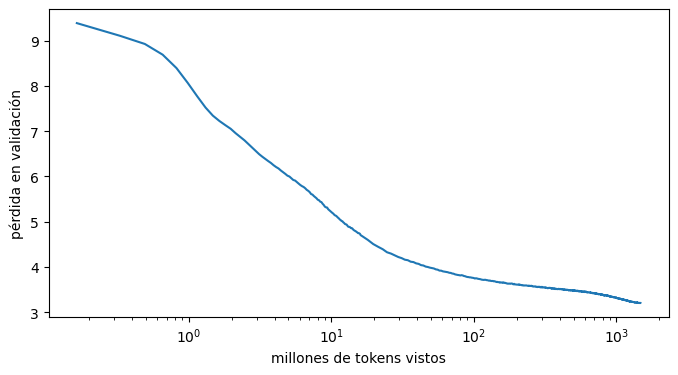

Pérdida al final: 3.2057


In [13]:
import matplotlib.pyplot as plt

def cargar(nombre: str) -> Transformer:
    guardado = torch.load(nombre, map_location="cpu")
    modelo = Transformer(Configuracion(**guardado["config"]))
    modelo.load_state_dict({clave: valor.float() for clave, valor
                            in guardado["pesos"].items()})
    return modelo.eval()


gpt = cargar("5-gpt-wikipedia.pt")
curva = pd.read_csv("5-gpt-wikipedia.csv")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curva["tokens_vistos"] / 1e6, curva["perdida_validacion"])
ax.set_xscale("log")
ax.set_xlabel("millones de tokens vistos")
ax.set_ylabel("pérdida en validación")
plt.show()
print("Pérdida al final:", curva["perdida_validacion"].iloc[-1])

El eje está en escala logarítmica: los primeros 100 millones de tokens la bajan a 3,8; los 1.375 millones restantes, a 3,21. En perplejidad (clase 4), e^3,21 ≈ 25: en promedio, como dudar entre 25 tokens.

## 7. ¿Funciona?

Los 5 tokens más probables:

In [14]:
def mejores(probabilidades: torch.Tensor, decodificar,
            k: int) -> list[str]:
    top = torch.topk(probabilidades, k)
    return [f"{decodificar([i]).strip()} ({p:.2f})" for p, i
            in zip(top.values.tolist(), top.indices.tolist())]


@torch.no_grad()
def siguientes(modelo: Transformer, texto: str, k: int = 5) -> list[str]:
    ids = torch.tensor([tokenizador.encode(texto).ids])
    probabilidades = torch.softmax(modelo(ids)[0, -1], dim=-1)
    return mejores(probabilidades, tokenizador.decode, k)


for frase in ["La capital de Chile es",
              "Gabriela Mistral recibió el Premio Nobel de",
              "Me senté a leer en un banco de la"]:
    print(frase)
    print("  ", siguientes(gpt, frase))

La capital de Chile es


   ['la (0.42)', 'Santiago (0.07)', 'el (0.07)', 'San (0.03)', 'La (0.03)']
Gabriela Mistral recibió el Premio Nobel de


   ['Literatura (0.31)', 'Física (0.14)', 'la (0.10)', 'Química (0.08)', 'F (0.07)']
Me senté a leer en un banco de la


   ['ciudad (0.08)', 'Universidad (0.07)', 'Ciudad (0.03)', 'India (0.02)', 'Unión (0.02)']


Para la capital, «la» (0,42) y «Santiago» (0,07); para el Nobel, «Literatura» (0,31). En «banco de la» no aparece «plaza»: propone «ciudad» y «Universidad».

Una frase del chat:

In [15]:
frase = "En el sur de Chile"  # la cambiamos por una del chat
temperatura = 1.0  # y probamos 0.5 o 2
print(continuar(gpt, frase, n_tokens=40, temperatura=temperatura))

En el sur de Chile, existe evidencia de la suma de fundadores y subsecretarios siglos antes.

Bibliografía 
 Zorda como alcalde y sufismo, 2008: http://www.mía física.com/


Así continuaba «La capital de Chile es» durante el entrenamiento:

In [16]:
import json

with open("5-gpt-wikipedia_evolucion.jsonl") as archivo:
    evolucion = [json.loads(linea) for linea in archivo]

for entrada in evolucion:
    if entrada["paso"] in (100, 1000, 10000, evolucion[-1]["paso"]):
        continuacion = entrada["predicciones"][0]["continuacion"]
        print(f"Paso {entrada['paso']:>6}: {continuacion}")

Paso    100: La capital de Chile es unaiscopal ahoracados constitucional masas, completaw todavía núcleos 78.aria,. intervenciónta muchos pilo de Ac cumb dearan
Paso   1000: La capital de Chile es una especie de balonmano masas turbiawdaquiahama. Se distribuye por Bolivia muchos países de Shang cumbisi,
Paso  10000: La capital de Chile es una colonia ahora pequeña en la Región Metropolitana del mismo nombre, propiedad de una antigua empresa perteneciente muchos cientos de señores de su
Paso  90011: La capital de Chile es una ciudad ahora pequeña al poniente del distrito homónimo. La ciudad se encuentra en el límite muchos cientos de kilómetros cumbres,


Paso 100: «una» y algunas comas. Paso 1.000: frases con forma de artículo («Se distribuye por Bolivia»). Al final, una ciudad y dónde queda, aunque Santiago no es pequeña. Las palabras que se repiten entre pasos («ahora», «muchos») vienen de usar la misma semilla.

Ahora, tres cabezas del modelo entrenado, cada una en una frase. Las capas y las cabezas se cuentan desde 0.

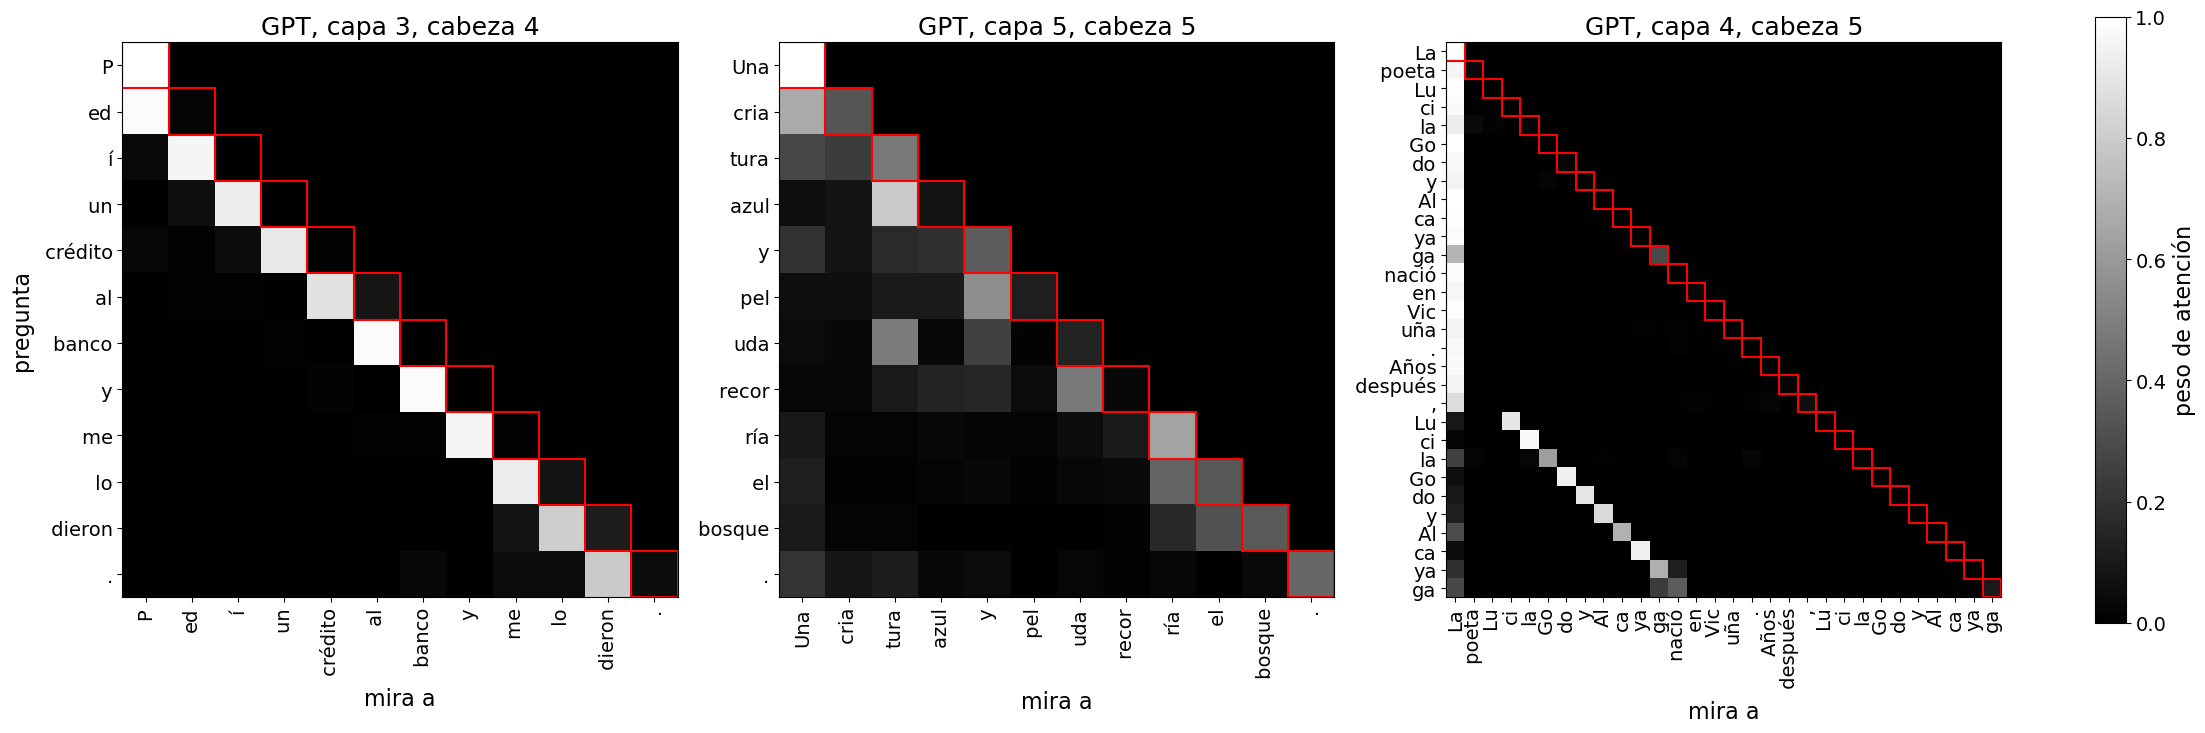

In [17]:
@torch.no_grad()
def pesos_de(modelo: Transformer, texto: str, capa: int,
             cabeza: int) -> pd.DataFrame:
    # cada fila es un token que mira; cada columna, un token al que mira
    # capas y cabezas se cuentan desde 0

    ids = torch.tensor([tokenizador.encode(texto).ids])

    x = modelo.embedding(ids) + modelo.posicion(torch.arange(ids.shape[1]))

    # recorremos los bloques anteriores para llegar a la entrada de la capa
    for bloque in modelo.bloques[:capa]:
        x = bloque(x)

    bloque = modelo.bloques[capa]
    # normalizamos la entrada como en Bloque.forward
    # .pesos calcula solo los pesos, sin combinar los values
    pesos = bloque.atencion.cabezas[cabeza].pesos(bloque.norma_atencion(x))

    tokens = [tokenizador.decode([i]) for i in ids[0].tolist()]
    return pd.DataFrame(pesos[0].numpy(), index=tokens, columns=tokens)


ejemplos = [  # (frase, capa, cabeza)
    ("Pedí un crédito al banco y me lo dieron.", 3, 4),
    ("Una criatura azul y peluda recorría el bosque.", 5, 5),
    ("La poeta Lucila Godoy Alcayaga nació en Vicuña. Años después, "
     "Lucila Godoy Alcayaga", 4, 5),
]
def mapas(modelo: Transformer, ejemplos: list[tuple[str, int, int]],
          nombre: str) -> None:
    fig, ejes = plt.subplots(1, 3, figsize=(22, 8), layout="constrained")
    for ax, (frase, capa, cabeza) in zip(ejes, ejemplos):
        tabla = pesos_de(modelo, frase, capa, cabeza)
        imagen = ax.imshow(tabla, cmap="gray", vmin=0, vmax=1)
        # la diagonal: cada token consigo mismo
        for i in range(len(tabla)):
            ax.add_patch(plt.Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False,
                                       edgecolor="red", linewidth=1.5))
        ax.set_xticks(range(len(tabla)), tabla.columns, rotation=90,
                      fontsize=14)
        ax.set_yticks(range(len(tabla)), tabla.index, fontsize=14)
        ax.set_title(f"{nombre}, capa {capa}, cabeza {cabeza}", fontsize=18)
        ax.set_xlabel("mira a", fontsize=16)
    ejes[0].set_ylabel("pregunta", fontsize=16)
    barra = fig.colorbar(imagen, ax=ejes, shrink=0.8)
    barra.set_label("peso de atención", fontsize=16)
    barra.ax.tick_params(labelsize=14)
    plt.show()


mapas(gpt, ejemplos, "GPT")

Capa 3, cabeza 4: cada token mira al anterior (« banco» → « al», 0,98).

Capa 5, cabeza 5: los adjetivos miran al sustantivo (« azul» → «tura», 0,79). En el ejemplo en inglés de 3Blue1Brown, «a fluffy blue creature», el sustantivo va al final y mira a los adjetivos; en español va primero y, con la máscara, no los ve.

Capa 4, cabeza 5: en la segunda mención, cada token mira al que lo siguió la primera vez (« Al» → «ca», 0,70). Es una cabeza de inducción (Olsson et al., 2022): copia lo que ya apareció. Apaguémosla:

In [18]:
def apagar(modulo, entrada, salida):
    return torch.zeros_like(salida)


cabeza_4_5 = gpt.bloques[4].atencion.cabezas[5]
for frase in ["La poeta Lucila Godoy Alcayaga nació en Vicuña. Años "
              "después, Lucila Godoy Al",
              "Años después, Lucila Godoy Al",
              "Años después, Gabriela M"]:
    print(frase)
    print("  normal:           ", siguientes(gpt, frase, k=3))
    # el hook reemplaza la salida con apagar, sin cambiar los pesos
    gancho = cabeza_4_5.register_forward_hook(apagar)
    print("  sin la cabeza 4,5:", siguientes(gpt, frase, k=3))
    gancho.remove()

La poeta Lucila Godoy Alcayaga nació en Vicuña. Años después, Lucila Godoy Al


  normal:            ['ca (0.90)', 'vara (0.01)', 'bur (0.01)']


  sin la cabeza 4,5: ['vara (0.17)', 'ca (0.14)', 'bor (0.06)']
Años después, Lucila Godoy Al


  normal:            ['vara (0.32)', 'var (0.04)', 'bor (0.04)']


  sin la cabeza 4,5: ['vara (0.31)', 'var (0.05)', 'bor (0.04)']
Años después, Gabriela M


  normal:            ['istra (0.80)', '. (0.02)', 'ella (0.01)']


  sin la cabeza 4,5: ['istra (0.82)', '. (0.03)', 'ina (0.01)']


Con la primera mención, «ca» tiene 0,90; sin la cabeza, 0,14; sin la mención, no aparece: el modelo lo copia de la frase. «Gabriela M» → «istra» no depende de la cabeza: ese nombre está en los pesos.

La tabla de embeddings también se aprendió. Como en la clase 3, sumemos y restemos vectores:

In [19]:
def analogia(tabla: torch.Tensor, ids: list[int],
             k: int = 3) -> torch.return_types.topk:
    # ids contiene los tokens a, b y c, en ese orden
    vector = tabla[ids[0]] - tabla[ids[1]] + tabla[ids[2]]
    cosenos = F.cosine_similarity(tabla, vector[None], dim=-1)
    # excluimos los tokens de partida de las respuestas
    cosenos[ids] = -1
    return torch.topk(cosenos, k)


tabla = gpt.embedding.weight.detach()
for palabras in [(" rey", " hombre", " mujer"),
                 (" padre", " hombre", " mujer"),
                 (" hermano", " hombre", " mujer"),
                 (" príncipe", " hombre", " mujer"),
                 (" París", " Francia", " Italia")]:
    ids = [tokenizador.encode(palabra).ids[0] for palabra in palabras]
    top = analogia(tabla, ids)
    print("{} -{} +{} →".format(*palabras),
          [f"{tokenizador.decode([i]).strip()} ({c:.2f})"
           for c, i in zip(top.values.tolist(), top.indices.tolist())])
print("Piezas de « tía»:",
      [tokenizador.decode([i]) for i in tokenizador.encode(" tía").ids])

 rey - hombre + mujer → ['reyes (0.68)', 'monarca (0.67)', 'emperador (0.66)']
 padre - hombre + mujer → ['madre (0.76)', 'padres (0.70)', 'abuelo (0.67)']
 hermano - hombre + mujer → ['hermana (0.79)', 'sobrino (0.72)', 'nieto (0.72)']
 príncipe - hombre + mujer → ['princesa (0.79)', 'lás (0.75)', 'varie (0.74)']
 París - Francia + Italia → ['Milán (0.72)', 'Roma (0.68)', 'Florencia (0.68)']
Piezas de « tía»: [' t', 'ía']


Padre, hermano y príncipe funcionan; rey no da reina. «tía» no se puede probar: se parte en « t» y «ía».

## 8. BERT

Devlin et al. (2019) vieron en la máscara de GPT la mayor limitación: «cada token solo puede atender a los tokens anteriores». BERT quita la máscara (`causal=False`) y cambia la tarea: adivinar tokens tapados mirando a los dos lados. Nuestra versión tapa el 15 % de los tokens con `<mascara>`:

In [20]:
id_mascara = tokenizador.token_to_id("<mascara>")


def lote_bert(ventanas: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    entradas = ventanas[:, :-1].clone()
    tapar = torch.rand(entradas.shape) < 0.15
    # -100 hace que la pérdida ignore los tokens que no tapamos
    respuestas = torch.where(tapar, entradas, -100)
    entradas[tapar] = id_mascara
    return entradas, respuestas


torch.manual_seed(20)
ids = tokenizador.encode("Me senté a leer en un banco de la plaza.<fin>").ids
entradas, respuestas = lote_bert(torch.tensor([ids]))
print("Entrada:  ", tokenizador.decode(entradas[0].tolist(),
                                       skip_special_tokens=False))
print("Respuestas:", [tokenizador.decode([i]) for i in respuestas[0]
                      if i != -100])

Entrada:   Me senté a leer en un<mascara> de la<mascara>.
Respuestas: [' banco', ' plaza']


El resto no cambia: el mismo `Transformer` con `causal=False`, entrenado igual que el GPT. Descarguemos el BERT entrenado así con la Wikipedia:

In [21]:
bert = cargar("5-bert-wikipedia.pt")
print("¿Usa máscara?", bert.config.causal)


@torch.no_grad()
def tapada(modelo: Transformer, texto: str, k: int = 5) -> list[str]:
    # el espacio antes de la palabra va dentro del token tapado
    ids = tokenizador.encode(texto.replace(" <mascara>", "<mascara>")).ids
    donde = ids.index(tokenizador.token_to_id("<mascara>"))
    probabilidades = torch.softmax(modelo(torch.tensor([ids]))[0, donde], -1)
    return mejores(probabilidades, tokenizador.decode, k)


for oracion in ["El <mascara> Central de Chile subió la tasa de interés.",
                "Me senté a leer en un <mascara> de la plaza."]:
    print(oracion, "→", tapada(bert, oracion))

¿Usa máscara? False


El <mascara> Central de Chile subió la tasa de interés. → ['Banco (0.52)', 'Parque (0.06)', 'Ferrocarril (0.06)', 'Distrito (0.05)', 'Gobierno (0.04)']


Me senté a leer en un <mascara> de la plaza. → ['lugar (0.06)', 'episodio (0.05)', 'sitio (0.02)', 'centro (0.02)', 'día (0.01)']


«Banco» (0,52) sale de lo que está a la derecha: a la izquierda solo está «El», todo lo que vería un GPT. En la plaza falla, como el GPT en la sección 7.

Las mismas frases de la sección 7, con cabezas de BERT:

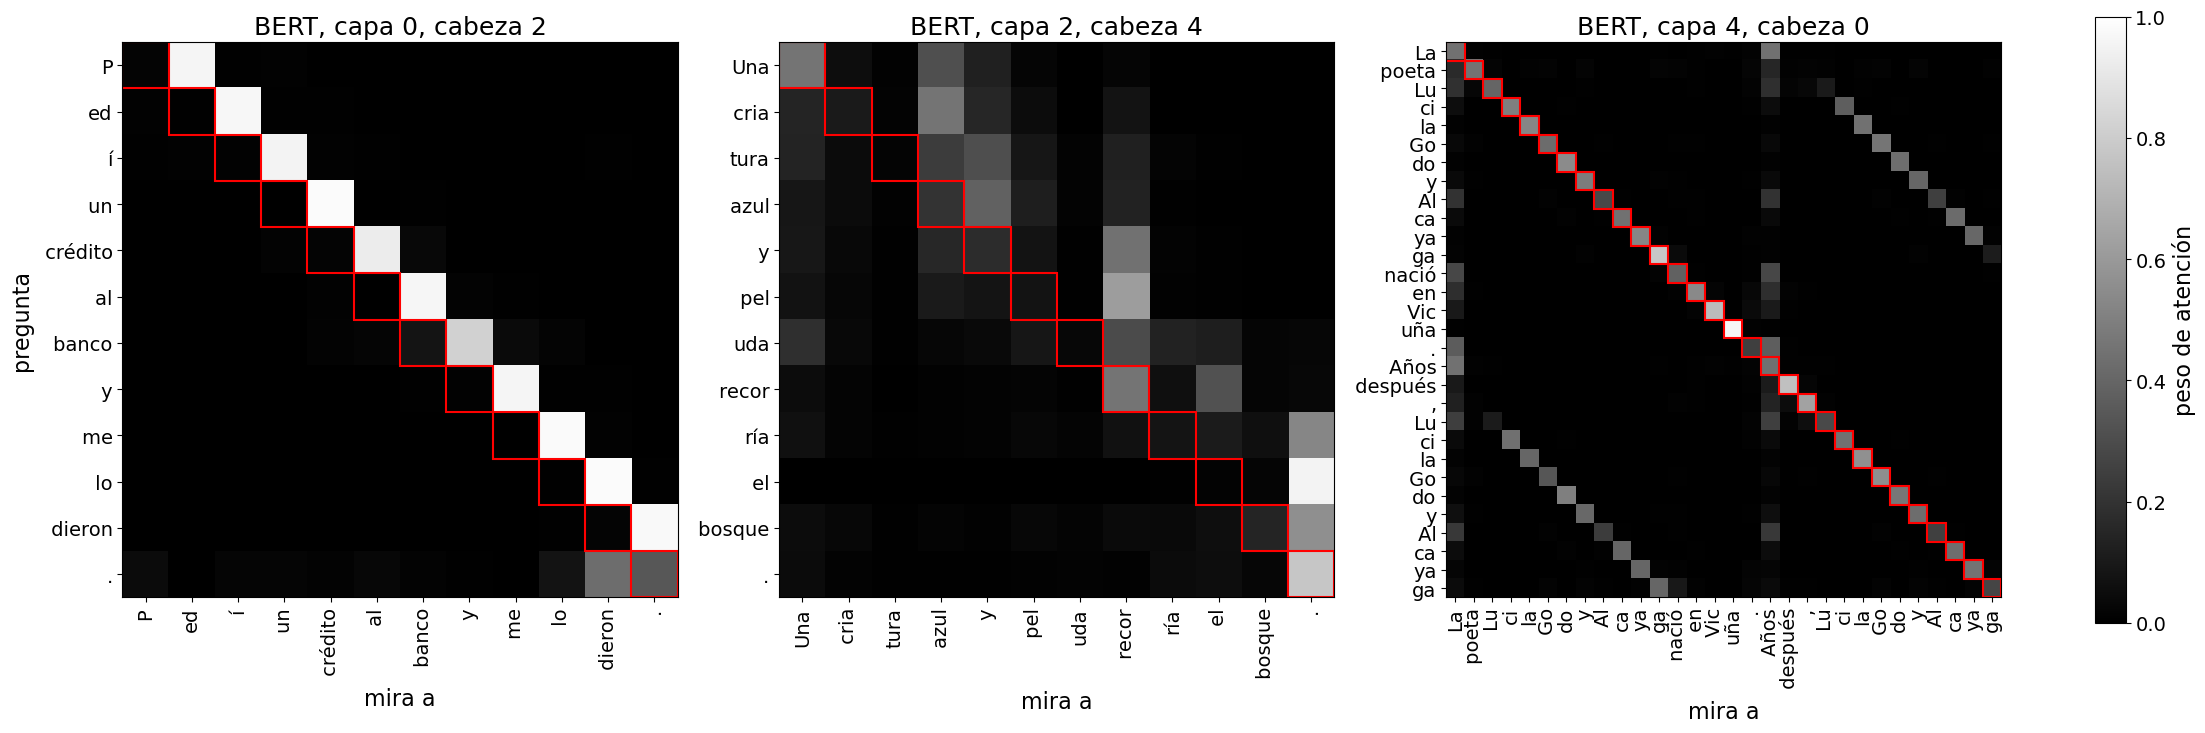

In [22]:
ejemplos_bert = [  # (frase, capa, cabeza)
    ("Pedí un crédito al banco y me lo dieron.", 0, 2),
    ("Una criatura azul y peluda recorría el bosque.", 2, 4),
    ("La poeta Lucila Godoy Alcayaga nació en Vicuña. Años después, "
     "Lucila Godoy Alcayaga", 4, 0),
]
mapas(bert, ejemplos_bert, "BERT")

Capa 0, cabeza 2: cada token mira al siguiente. Capa 2, cabeza 4: « cria» mira hacia adelante, a « azul» (0,45), como en el ejemplo de 3Blue1Brown. Capa 4, cabeza 0: cada token se mira a sí mismo y a su copia en la otra mención, hacia los dos lados.

GPT sirve para escribir; BERT, para representar un texto entero.

## 9. Un modelo más grande

`datificate/gpt2-small-spanish` es un GPT-2 de 124 millones de parámetros, el GPT-2 chico en inglés, afinado (fine-tuned) con la Wikipedia en español. BETO (Cañete et al., 2020) es un BERT de 110 millones, del DCC, entrenado con unos 3.000 millones de palabras.

In [23]:
from transformers import (AutoModelForCausalLM, AutoModelForMaskedLM,
                          AutoTokenizer)

tokenizador_gpt2 = AutoTokenizer.from_pretrained(
    "datificate/gpt2-small-spanish")
gpt2 = AutoModelForCausalLM.from_pretrained(
    "datificate/gpt2-small-spanish").eval()
tokenizador_beto = AutoTokenizer.from_pretrained(
    "dccuchile/bert-base-spanish-wwm-uncased")
beto = AutoModelForMaskedLM.from_pretrained(
    "dccuchile/bert-base-spanish-wwm-uncased").eval()
print("Parámetros de GPT-2:", f"{contar(gpt2):,}")
print("Parámetros de BETO: ", f"{contar(beto):,}")

Parámetros de GPT-2: 124,439,808
Parámetros de BETO:  109,883,418


In [24]:
for frase in ["La capital de Chile es",
              "Gabriela Mistral recibió el Premio Nobel de",
              "La torre Eiffel está en la ciudad de",
              "Michael Jordan juega al",
              "Me senté a leer en un banco de la"]:
    entradas = tokenizador_gpt2(frase, return_tensors="pt")
    with torch.no_grad():
        puntajes = gpt2(**entradas).logits[0, -1]
    print(frase)
    print("  nuestro GPT:", siguientes(gpt, frase, k=3))
    print("  GPT-2:      ", mejores(torch.softmax(puntajes, dim=-1),
                                    tokenizador_gpt2.decode, 3))

La capital de Chile es


  nuestro GPT: ['la (0.42)', 'Santiago (0.07)', 'el (0.07)']
  GPT-2:       ['la (0.32)', 'el (0.13)', 'Concepción (0.07)']


Gabriela Mistral recibió el Premio Nobel de


  nuestro GPT: ['Literatura (0.31)', 'Física (0.14)', 'la (0.10)']
  GPT-2:       ['Literatura (0.50)', 'la (0.24)', 'Medicina (0.05)']


La torre Eiffel está en la ciudad de


  nuestro GPT: ['Le (0.02)', 'Múnich (0.02)', 'G (0.02)']
  GPT-2:       ['Nueva (0.23)', 'París (0.14)', 'Buenos (0.03)']


Michael Jordan juega al


  nuestro GPT: ['fútbol (0.69)', 'baloncesto (0.07)', 'h (0.01)']
  GPT-2:       ['fútbol (0.46)', 'baloncesto (0.06)', 'lado (0.05)']


Me senté a leer en un banco de la


  nuestro GPT: ['ciudad (0.08)', 'Universidad (0.07)', 'Ciudad (0.03)']
  GPT-2:       ['ciudad (0.37)', 'calle (0.15)', 'capital (0.06)']


GPT-2 sabe algo más («Literatura» 0,50, «París» 0,14), pero también dice que Michael Jordan juega fútbol y tampoco propone «plaza».

Las mismas sumas de vectores con la tabla de GPT-2, donde «tía» es un token:

In [25]:
tabla_gpt2 = gpt2.get_input_embeddings().weight.detach()
for palabras in [(" rey", " hombre", " mujer"),
                 (" tío", " hombre", " mujer"),
                 (" París", " Francia", " Italia")]:
    ids = [tokenizador_gpt2(palabra)["input_ids"][0] for palabra in palabras]
    top = analogia(tabla_gpt2, ids)
    print("{} -{} +{} →".format(*palabras),
          [f"{tokenizador_gpt2.decode([i]).strip()} ({c:.2f})"
           for c, i in zip(top.values.tolist(), top.indices.tolist())])

 rey - hombre + mujer → ['reina (0.88)', 'esposa (0.88)', 'emperador (0.87)']


 tío - hombre + mujer → ['abuelo (0.89)', 'sobrino (0.89)', 'tía (0.89)']


 París - Francia + Italia → ['italiano (0.91)', 'Roma (0.91)', 'italianos (0.90)']


Con GPT-2, «reina» queda primera (empatada con «esposa», 0,88) y «tía», tercera.

BETO contra nuestro BERT:

In [26]:
for oracion in ["Me senté a leer en un <mascara> de la plaza.",
                "La capital de Chile es <mascara>.",
                "La torre Eiffel está en <mascara>.",
                "Michael Jordan juega al <mascara>."]:
    entradas = tokenizador_beto(
        oracion.replace("<mascara>", tokenizador_beto.mask_token),
        return_tensors="pt")
    donde = entradas["input_ids"][0].tolist().index(
        tokenizador_beto.mask_token_id)
    with torch.no_grad():
        puntajes = beto(**entradas).logits[0, donde]
    print(oracion)
    print("  nuestro BERT:", tapada(bert, oracion, k=3))
    print("  BETO:        ", mejores(torch.softmax(puntajes, dim=-1),
                                     tokenizador_beto.decode, 3))

Me senté a leer en un <mascara> de la plaza.


  nuestro BERT: ['lugar (0.06)', 'episodio (0.05)', 'sitio (0.02)']
  BETO:         ['banco (0.20)', 'cartel (0.14)', 'libro (0.11)']


La capital de Chile es <mascara>.


  nuestro BERT: ['2 (0.09)', '1 (0.06)', '4 (0.06)']
  BETO:         ['santiago (0.94)', 'chile (0.04)', '[UNK] (0.00)']


La torre Eiffel está en <mascara>.


  nuestro BERT: ['construcción (0.09)', '2 (0.06)', '4 (0.06)']
  BETO:         ['francia (0.39)', 'paris (0.28)', '[UNK] (0.07)']


Michael Jordan juega al <mascara>.


  nuestro BERT: ['2 (0.11)', '1 (0.05)', '0 (0.05)']
  BETO:         ['contrario (0.21)', 'campo (0.12)', 'centro (0.07)']


BETO acierta «banco» (0,20), «santiago» (0,94) y la torre Eiffel; nuestro BERT, ninguna. Con Michael Jordan fallan los dos. BETO es uncased: pasa todo a minúsculas, pero conserva las tildes.

## 10. Cierre

Cada token parte con su embedding y su posición. En cada bloque, la atención le suma lo que toma de los tokens anteriores, con pesos que salen de queries y keys, y el feed-forward le suma lo que el modelo aprendió. Al final, el último vector da una probabilidad a cada token. Todas las matrices salieron de predecir el token siguiente.

Rodrigo nos cuenta qué se hace hoy con modelos como BERT.

**Lecturas**

- Sanderson, G. (2024). *Deep Learning*, capítulos 5, 6 y 7. 3Blue1Brown. Videos y lecciones escritas en https://www.3blue1brown.com/topics/neural-networks.
- Karpathy, A. (2023). «Let's build GPT: from scratch, in code, spelled out». https://www.youtube.com/watch?v=kCc8FmEb1nY
- Raschka, S. (2024). *Build a Large Language Model (From Scratch)*. Manning. El repositorio (https://github.com/rasbt/LLMs-from-scratch) muestra cómo se pasa de un modelo como este a uno actual.
- Jurafsky, D. y Martin, J. H. *Speech and Language Processing*, 3.ª ed. (borrador), capítulo sobre Transformers. https://web.stanford.edu/~jurafsky/slp3/
- Radford, A., Narasimhan, K., Salimans, T. y Sutskever, I. (2018). «Improving Language Understanding by Generative Pre-Training». OpenAI.
- Vaswani, A. et al. (2017). «Attention Is All You Need». *NeurIPS*.
- Olsson, C. et al. (2022). «In-context Learning and Induction Heads». Anthropic. https://arxiv.org/abs/2209.11895
- Cañete, J. et al. (2020). «Spanish Pre-Trained BERT Model and Evaluation Data». PML4DC, ICLR. https://github.com/dccuchile/beto